In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm


import os
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

In [46]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
NVIDIA GeForce RTX 4090


In [47]:
#Import SAM2
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 imported successfully")

SAM2 imported successfully


In [48]:
#Find SAM2 checkpoint
possible_checkpoints = [
    "/home/zahranadeem/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2_repo/checkpoints/sam2_hiera_small.pt",
]

checkpoint = None

for p in possible_checkpoints:
    if os.path.exists(p):
        checkpoint = p
        break

print("Checkpoint:", checkpoint)

assert checkpoint is not None, "SAM2 checkpoint not found"

Checkpoint: /home/zahranadeem/checkpoints/sam2_hiera_small.pt


In [49]:
#Load SAM2 
config = "sam2_hiera_s.yaml"

sam2_model = build_sam2(
    config,
    checkpoint,
    device=device
)

predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully")

SAM2 loaded successfully


In [50]:
#Load VegANN
from datasets import load_dataset
dataset = load_dataset(
            "simonMadec/VegAnn"
)

print(dataset)
print(dataset["train"][10].keys())

# Create 80/20 split
split_dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42
)

train_dataset = split_dataset["train"]
val_dataset = split_dataset["test"]

print("\nTrain size:", len(train_dataset))
print("Validation size:", len(val_dataset))




DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])

Train size: 3020
Validation size: 755


In [51]:
#Loading AGRICLIP 
agriclip_paths = [
    "/home/zahranadeem/AgriCLIP",
    "/home/zahranadeem/AgriCLIP/AgriCLIP_alignment",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment",
]

for p in agriclip_paths:
    if os.path.exists(p) and p not in sys.path:
        sys.path.append(p)

print("Paths added")

Paths added


In [52]:
#Import AgriCLIP modules 
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("AgriCLIP modules imported")

AgriCLIP modules imported


In [53]:
#Loading DINO 
model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_path_candidates = [
    "/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/dino_pretrain.pth",
]

dino_path = None

for p in dino_path_candidates:
    if os.path.exists(p):
        dino_path = p
        break

print("DINO path:", dino_path)

model.load_state_dict(
    torch.load(dino_path, map_location="cpu")
)

model = model.to(device)
model.eval()

def forward_features(x):
    return model(x)

model.forward_features = forward_features

print("DINO loaded")

DINO path: /home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth
DINO loaded


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [54]:
#Load Fine tuned AgriCLIP aligner 
text_to_concept = TextToConcept(model, "Dino")

aligner_path = "/home/zahranadeem/thesis/vegann_plantvillage_aligner.pth"

text_to_concept.load_linear_aligner(aligner_path)

print("VegAnn + PlantVillage fine-tuned aligner loaded")

VegAnn + PlantVillage fine-tuned aligner loaded


In [55]:
def predict_agriclip_species(pil_image):
    img_tensor = transform(pil_image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = species_classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()
    top5 = np.argsort(scores)[-5:][::-1]
    pred_species = species_list[top5[0]]

    return pred_species, top5, scores

In [57]:
sample = val_dataset[idx]

pred_species, top5, scores = predict_agriclip_species(sample["image"])

print("GT:", sample["Species"])
print("Pred:", pred_species)

GT: Maize
Pred: Raspberry


In [59]:
#AgriCLIP species prediction 
# AgriCLIP species prediction setup

from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

species_list = sorted(list(set(val_dataset["Species"])))

species_classifier = text_to_concept.get_zero_shot_classifier(
    species_list,
    prompts=[
        "An agricultural image showing {} plants."
    ]
)

def predict_agriclip_species(pil_image):
    img_tensor = transform(pil_image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = species_classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()
    top5 = np.argsort(scores)[-5:][::-1]
    predicted_species = species_list[top5[0]]

    return predicted_species, top5, scores

print("AgriCLIP species classifier ready")

AgriCLIP species classifier ready


In [60]:
sample = val_dataset[idx]

predicted_species, top5, scores = predict_agriclip_species(sample["image"])

print("Ground Truth:", sample["Species"])
print("\nAgriCLIP Top-5:")

for i in top5:
    print(species_list[i], scores[i])

print("\nPredicted species:", predicted_species)

Ground Truth: Maize

AgriCLIP Top-5:
Pepper 0.5574981
Na 0.5501671
Tabacco 0.54962033
Raspberry 0.5463324
Mix 0.5374913

Predicted species: Pepper


In [61]:
#Defining prediction function 
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

def predict_agriclip_species(pil_image):
    img_tensor = transform(pil_image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = species_classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()

    top5 = np.argsort(scores)[-5:][::-1]

    pred_species = species_list[top5[0]]

    return pred_species, top5, scores

print("predict_agriclip_species function created")

predict_agriclip_species function created


In [64]:
print(predict_agriclip_species)

<function predict_agriclip_species at 0x78169ffd7490>


In [65]:
#Creating automatic vegetation box without GT 
#Image itself is used to estimate vegetation location, while 
#Agriclip supplies the semantic label
from scipy import ndimage

def get_vegetation_box_from_image_full(image, padding=10, percentile=70):
    """
    Automatic vegetation box using Excess Green.
    Does NOT use GT mask.
    """

    img = image.astype(np.float32) / 255.0

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = 2 * g - r - b

    threshold = np.percentile(exg, percentile)

    veg_mask = exg > threshold

    ys, xs = np.where(veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = image.shape[:2]
        box = np.array([
            W // 4,
            H // 4,
            3 * W // 4,
            3 * H // 4
        ])
        return box, veg_mask

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    box = np.array([x1, y1, x2, y2])

    return box, veg_mask

In [66]:
def run_sam2_box_prompt(image, box):
    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [67]:
def compute_iou_dice(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0

    dice = (2 * intersection) / (pred.sum() + gt.sum()) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice

In [81]:
final_results = []

N = 500

for idx in tqdm(range(N)):

    sample = val_dataset[idx]

    pil_image = sample["image"]
    image = np.array(pil_image)
    mask = np.array(sample["mask"])

    gt_mask = mask == 0

    if gt_mask.sum() == 0:
        continue

    pred_species, top5, species_scores = predict_agriclip_species(pil_image)

    auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
        image,
        padding=10,
        percentile=70
    )

    pred_mask = run_sam2_box_prompt(image, auto_box)

    iou, dice = compute_iou_dice(pred_mask, gt_mask)

    final_results.append({
        "idx": idx,
        "GT Species": sample["Species"],
        "AgriCLIP Pred Species": pred_species,
        "IoU": iou,
        "Dice": dice
    })

final_results_df = pd.DataFrame(final_results)

final_results_df.head()

100%|██████████| 500/500 [00:19<00:00, 25.35it/s]


,idx,GT Species,AgriCLIP Pred Species,IoU,Dice
0,0,Wheat,Na,0.004852,0.009657
1,1,Potato,Na,0.029652,0.057597
2,2,Rice,Potato,0.914854,0.955534
3,3,Mix,Pepper,0.086612,0.159416
4,4,Wheat,Na,0.003315,0.006609


In [82]:
final_mean_iou = final_results_df["IoU"].mean()
final_mean_dice = final_results_df["Dice"].mean()

print(f"Final AgriCLIP + SAM2 Mean IoU: {final_mean_iou*100:.2f}%")
print(f"Final AgriCLIP + SAM2 Mean Dice: {final_mean_dice*100:.2f}%")

Final AgriCLIP + SAM2 Mean IoU: 18.31%
Final AgriCLIP + SAM2 Mean Dice: 22.35%


In [83]:
final_summary = pd.DataFrame({
    "Method": [
        "SAM2 + Center Point",
        "SAM2 + GT Box",
        "Auto Vegetation Box + SAM2",
        "AgriCLIP + Auto Box + SAM2"
    ],
    "Mean IoU": [
        0.1052,
        0.4128,
        0.4015,
        final_mean_iou
    ],
    "Mean Dice": [
        0.1236,
        0.5038,
        0.4868,
        final_mean_dice
    ]
})

final_summary_percent = final_summary.copy()

final_summary_percent["Mean IoU"] = final_summary_percent["Mean IoU"].apply(
    lambda x: f"{x*100:.2f}%"
)

final_summary_percent["Mean Dice"] = final_summary_percent["Mean Dice"].apply(
    lambda x: f"{x*100:.2f}%"
)

final_summary_percent

,Method,Mean IoU,Mean Dice
0,SAM2 + Center Point,10.52%,12.36%
1,SAM2 + GT Box,41.28%,50.38%
2,Auto Vegetation Box + SAM2,40.15%,48.68%
3,AgriCLIP + Auto Box + SAM2,18.31%,22.35%


                       Method   Mean IoU  Mean Dice
0         SAM2 + Center Point  10.520000   12.36000
1               SAM2 + GT Box  41.280000   50.38000
2             Auto Box + SAM2  40.150000   48.68000
3  AgriCLIP + Auto Box + SAM2  18.306645   22.35179


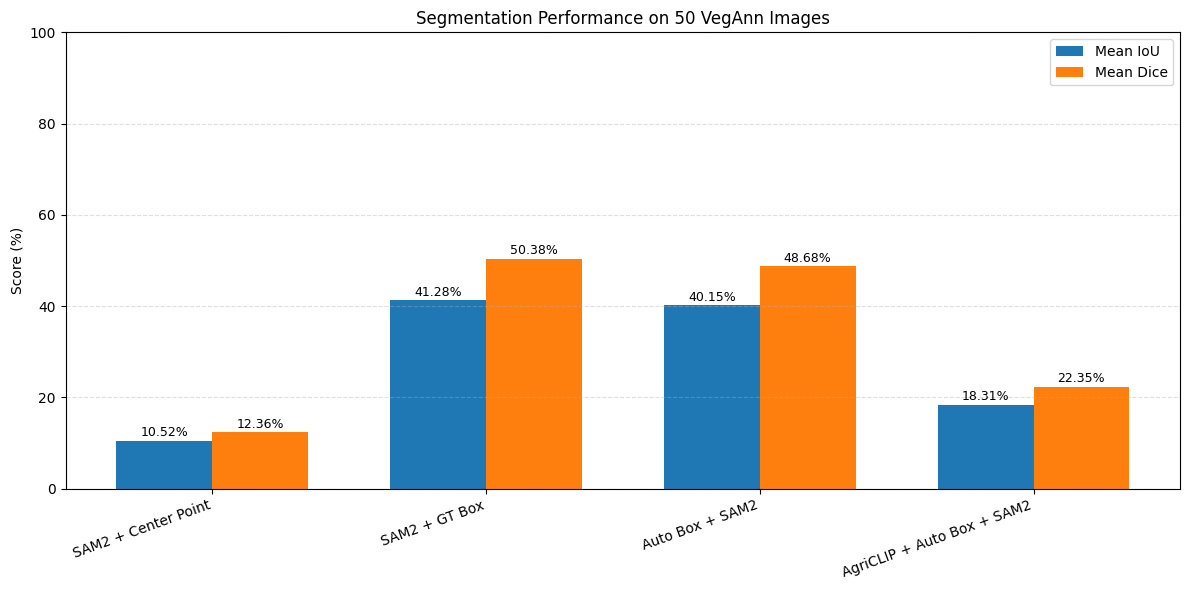

In [84]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "SAM2 + Center Point",
        "SAM2 + GT Box",
        "Auto Box + SAM2",
        "AgriCLIP + Auto Box + SAM2"
    ],
    "Mean IoU": [
        10.52,
        41.28,
        40.15,
        final_mean_iou*100
    ],
    "Mean Dice": [
        12.36,
        50.38,
        48.68,
        final_mean_dice*100
    ]
})

print(results)

methods = results["Method"].tolist()
iou_scores = results["Mean IoU"].tolist()
dice_scores = results["Mean Dice"].tolist()

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width/2, iou_scores, width, label="Mean IoU")
plt.bar(x + width/2, dice_scores, width, label="Mean Dice")

plt.xticks(x, methods, rotation=20, ha="right")
plt.ylabel("Score (%)")
plt.title("Segmentation Performance on 50 VegAnn Images")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(iou_scores):
    plt.text(i - width/2, v + 1, f"{v:.2f}%", ha="center", fontsize=9)

for i, v in enumerate(dice_scores):
    plt.text(i + width/2, v + 1, f"{v:.2f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("final_agriclip_sam2_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [85]:
import pandas as pd

comparison_table = pd.DataFrame({
    "Number of Images": [50, 100, 200, 500],
    "Mean IoU (%)": [17.30, 21.71, 18.99, 18.31],
    "Mean Dice (%)": [21.16, 25.72, 23.34, 22.35]
})

comparison_table

,Number of Images,Mean IoU (%),Mean Dice (%)
0,50,17.30,21.16
1,100,21.71,25.72
2,200,18.99,23.34
3,500,18.31,22.35


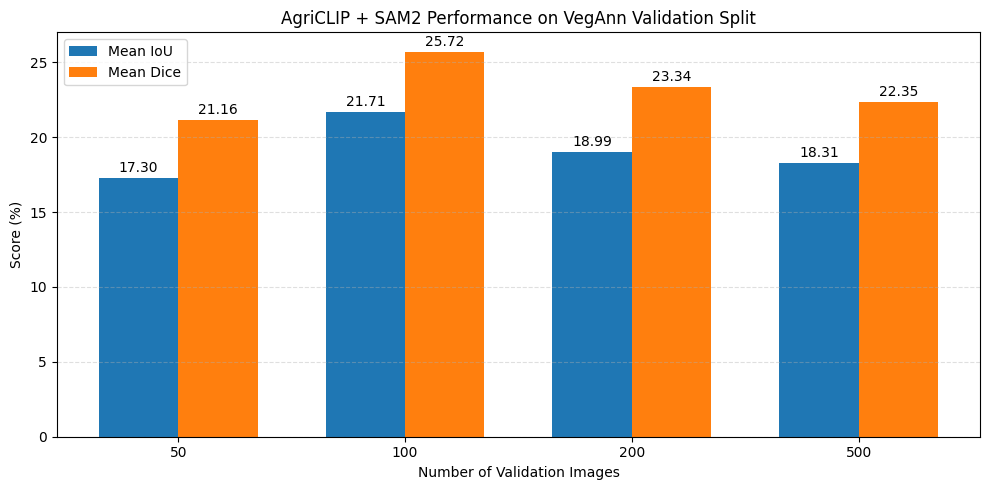

In [88]:
import matplotlib.pyplot as plt
import numpy as np

images = comparison_table["Number of Images"]
iou = comparison_table["Mean IoU (%)"]
dice = comparison_table["Mean Dice (%)"]

x = np.arange(len(images))
width = 0.35

plt.figure(figsize=(10,5))

plt.bar(
    x - width/2,
    iou,
    width,
    label="Mean IoU"
)

plt.bar(
    x + width/2,
    dice,
    width,
    label="Mean Dice"
)

plt.xticks(x, images)
plt.xlabel("Number of Validation Images")
plt.ylabel("Score (%)")
plt.title("AgriCLIP + SAM2 Performance on VegAnn Validation Split")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(iou):
    plt.text(i - width/2, v + 0.4, f"{v:.2f}", ha="center")

for i, v in enumerate(dice):
    plt.text(i + width/2, v + 0.4, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.savefig("vegann_val_split_comparison.png", dpi=300)
plt.show()